# FAQ Semantic Understanding Using Word2Vec, Sentence Embeddings, Contextual Embeddings and Transformers

## 1. Problem Statement

In this experiment, we explore how different embedding techniques convert textual information into numerical representations and how these representations help machines understand relationships between words and sentences.

We will create our own FAQ dataset based on an AI/ML learning programme and apply three embedding techniques:

1. **Word Embeddings using Word2Vec** – To represent individual words as numerical vectors.
2. **Sentence Embeddings using Sentence Transformers** – To represent complete sentences as numerical vectors.
3. **Contextual Embeddings using BERT** – To generate word representations based on their surrounding context.

We will also explore **cosine similarity** to measure the similarity between embedding vectors and identify semantically related questions.

### Objectives

- Create a meaningful FAQ dataset with questions and answers.
- Understand how text is tokenized before generating embeddings.
- Generate and inspect word embeddings using Word2Vec.
- Generate sentence embeddings using a pretrained Sentence Transformer.
- Generate contextual token embeddings using BERT.
- Compare words and sentences using cosine similarity.
- Understand how Transformers generate contextual representations.
- Analyze the results and document observations.

### Tools and Libraries

Python, Pandas, NumPy, Gensim, Sentence Transformers, Hugging Face Transformers and PyTorch.

In [31]:
import pandas as pd

# Create our own AI/ML learning programme FAQ dataset

faq_data = [
    ("F01", "Machine Learning",
     "What is machine learning?",
     "Machine learning enables computers to learn patterns from data and make predictions."),

    ("F02", "Machine Learning",
     "How does ML work?",
     "ML algorithms learn patterns from training data and use them to make predictions."),

    ("F03", "Deep Learning",
     "What is deep learning?",
     "Deep learning uses multi-layer neural networks to learn complex patterns."),

    ("F04", "Deep Learning",
     "How is deep learning different from machine learning?",
     "Deep learning uses multiple neural network layers, while traditional machine learning uses various algorithms."),

    ("F05", "NLP",
     "What is natural language processing?",
     "NLP enables computers to understand, process and generate human language."),

    ("F06", "Python",
     "How can I start learning Python?",
     "Start with Python fundamentals, including variables, data types, loops, functions and data structures."),

    ("F07", "Embeddings",
     "What are word embeddings?",
     "Word embeddings represent individual words as dense numerical vectors."),

    ("F08", "Embeddings",
     "What is the purpose of sentence embeddings?",
     "Sentence embeddings convert complete sentences into numerical vectors that capture their meaning."),

    ("F09", "Neural Networks",
     "How does a neural network learn?",
     "A neural network learns by adjusting weights and biases through forward propagation and backpropagation."),

    ("F10", "Transformers",
     "What is the attention mechanism in Transformers?",
     "Attention helps a Transformer identify important relationships between tokens in a sequence."),

    ("F11", "Transformers",
     "Why are positional encodings used in Transformers?",
     "Positional encodings provide information about the position and order of tokens in a sequence."),

    ("F12", "RAG",
     "What is Retrieval Augmented Generation?",
     "RAG retrieves relevant information from external documents and uses it to generate context-aware responses."),

    ("F13", "RAG",
     "How does RAG retrieve relevant documents?",
     "RAG converts queries and documents into embeddings and uses similarity search to retrieve relevant content."),

    ("F14", "Tokenization",
     "What is tokenization in NLP?",
     "Tokenization divides text into smaller units called tokens before further processing."),

    ("F15", "Tokenization",
     "What is an API authentication token?",
     "An API authentication token is a credential used to verify access to an application or service."),

    ("F16", "Model Training",
     "How can I reduce overfitting in machine learning?",
     "Overfitting can be reduced using regularization, dropout, early stopping and suitable training data."),

    ("F17", "Model Evaluation",
     "Which metrics are used to evaluate a classification model?",
     "Accuracy, precision, recall, F1-score and ROC-AUC are commonly used classification metrics."),

    ("F18", "Data Science",
     "What is the difference between data analysis and machine learning?",
     "Data analysis focuses on examining data to gain insights, while machine learning learns patterns to make predictions.")
]

# Convert the FAQ records into a DataFrame
df = pd.DataFrame(
    faq_data,
    columns=["FAQ_ID", "Category", "Question", "Answer"]
)

# Display the dataset
display(df)

,FAQ_ID,Category,Question,Answer
0,F01,Machine Learning,What is machine learning?,Machine learning enables computers to learn pa...
1,F02,Machine Learning,How does ML work?,ML algorithms learn patterns from training dat...
2,F03,Deep Learning,What is deep learning?,Deep learning uses multi-layer neural networks...
3,F04,Deep Learning,How is deep learning different from machine le...,Deep learning uses multiple neural network lay...
4,F05,NLP,What is natural language processing?,"NLP enables computers to understand, process a..."
5,F06,Python,How can I start learning Python?,"Start with Python fundamentals, including vari..."
6,F07,Embeddings,What are word embeddings?,Word embeddings represent individual words as ...
7,F08,Embeddings,What is the purpose of sentence embeddings?,Sentence embeddings convert complete sentences...
8,F09,Neural Networks,How does a neural network learn?,A neural network learns by adjusting weights a...
9,F10,Transformers,What is the attention mechanism in Transformers?,Attention helps a Transformer identify importa...


In [32]:
# Understand the structure of our FAQ dataset

print("Number of FAQs:", len(df))
print("Number of Columns:", df.shape[1])

print("\nColumn Information:")
print(df.info())

print("\nFAQs per Category:")
print(df["Category"].value_counts())

Number of FAQs: 18
Number of Columns: 4

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   FAQ_ID    18 non-null     object
 1   Category  18 non-null     object
 2   Question  18 non-null     object
 3   Answer    18 non-null     object
dtypes: object(4)
memory usage: 708.0+ bytes
None

FAQs per Category:
Category
Machine Learning    2
Deep Learning       2
Transformers        2
Embeddings          2
RAG                 2
Tokenization        2
Python              1
NLP                 1
Neural Networks     1
Model Training      1
Model Evaluation    1
Data Science        1
Name: count, dtype: int64


## 2. Text Preparation and Tokenization

Tokenization is the process of breaking text into smaller units called tokens.

In this experiment, we will tokenize the FAQ questions and answers to prepare the text for Word2Vec.

We will use Gensim's `simple_preprocess()` function, which converts text into lowercase tokens and removes punctuation and certain short tokens.

### Objective
- Separate FAQ questions and answers.
- Convert text into tokens.
- Inspect the tokenized output.
- Prepare the tokenized questions for Word2Vec training.

In [33]:
!pip install gensim

from gensim.utils import simple_preprocess

print("Gensim imported successfully!")

Gensim imported successfully!


In [34]:


from gensim.utils import simple_preprocess

# Extract questions and answers
questions = df["Question"].tolist()
answers = df["Answer"].tolist()

# Tokenize FAQ questions
tokenized_questions = [
    simple_preprocess(question)
    for question in questions
]

# Tokenize FAQ answers
tokenized_answers = [
    simple_preprocess(answer)
    for answer in answers
]

# Display tokenization results
for i in range(3):
    print(f"Original Question: {questions[i]}")
    print(f"Tokenized Question: {tokenized_questions[i]}")
    print("-" * 80)

Original Question: What is machine learning?
Tokenized Question: ['what', 'is', 'machine', 'learning']
--------------------------------------------------------------------------------
Original Question: How does ML work?
Tokenized Question: ['how', 'does', 'ml', 'work']
--------------------------------------------------------------------------------
Original Question: What is deep learning?
Tokenized Question: ['what', 'is', 'deep', 'learning']
--------------------------------------------------------------------------------


In [35]:
for i in range(3):
    print(f"Original Answer: {answers[i]}")
    print(f"Tokenized Answer: {tokenized_answers[i]}")
    print("-" * 80)

Original Answer: Machine learning enables computers to learn patterns from data and make predictions.
Tokenized Answer: ['machine', 'learning', 'enables', 'computers', 'to', 'learn', 'patterns', 'from', 'data', 'and', 'make', 'predictions']
--------------------------------------------------------------------------------
Original Answer: ML algorithms learn patterns from training data and use them to make predictions.
Tokenized Answer: ['ml', 'algorithms', 'learn', 'patterns', 'from', 'training', 'data', 'and', 'use', 'them', 'to', 'make', 'predictions']
--------------------------------------------------------------------------------
Original Answer: Deep learning uses multi-layer neural networks to learn complex patterns.
Tokenized Answer: ['deep', 'learning', 'uses', 'multi', 'layer', 'neural', 'networks', 'to', 'learn', 'complex', 'patterns']
--------------------------------------------------------------------------------


====================================================================================

# Word Embeddings using Word2Vec

====================================================================================

## 3. Word Embeddings using Word2Vec

Word2Vec is a technique that learns numerical representations of individual words based on their surrounding words and usage patterns.

In this experiment, we will train a Word2Vec model using our FAQ questions and answers.

### Objectives
- Train a Word2Vec model.
- Generate numerical vectors for individual words.
- Understand the dimensions of word embeddings.
- Find similar words using cosine similarity.

In [36]:
# Combine tokenized questions and answers
training_sentences = tokenized_questions + tokenized_answers

print("Total training sentences:", len(training_sentences))
print("\nSample training sentences:")

for sentence in training_sentences[:3]:
    print(sentence)

Total training sentences: 36

Sample training sentences:
['what', 'is', 'machine', 'learning']
['how', 'does', 'ml', 'work']
['what', 'is', 'deep', 'learning']


### 3.1 Training the Word2Vec Model

We will use Gensim's Word2Vec algorithm to learn word embeddings from our FAQ dataset.

Model parameters:
- `vector_size=100`: Generates a 100-dimensional vector for each word.
- `window=5`: Considers up to 5 neighboring words on either side.
- `min_count=1`: Includes words that appear at least once.
- `sg=1`: Uses the Skip-Gram architecture.
- `epochs=100`: Trains the model over the dataset 100 times.

In [37]:
from gensim.models import Word2Vec

# Initialize and train the Word2Vec model
word2vec_model = Word2Vec(
    sentences=training_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    sg=1,
    epochs=100,
    seed=42
)

print("Word2Vec model trained successfully!")

Word2Vec model trained successfully!


### 3.2 Exploring the Word2Vec Vocabulary

After training, Word2Vec creates a vocabulary containing all unique words found in the training sentences.

We will inspect:
- Total number of unique words.
- Sample words from the vocabulary.

In [38]:
# Retrieve the vocabulary
vocabulary = list(word2vec_model.wv.index_to_key)

print("Total unique words:", len(vocabulary))
print("\nSample vocabulary words:")
print(vocabulary[:20])

Total unique words: 172

Sample vocabulary words:
['and', 'learning', 'to', 'is', 'what', 'data', 'machine', 'in', 'how', 'uses', 'embeddings', 'patterns', 'used', 'learn', 'neural', 'the', 'are', 'from', 'deep', 'tokens']


### 3.3 Generating Word Embeddings

Each word in the trained Word2Vec vocabulary is represented by a numerical vector.

Our model generates a 100-dimensional vector for every word.

In [39]:
# Retrieve the embedding for a word
word = "learning"

word_vector = word2vec_model.wv[word]

print("Word:", word)
print("Embedding vector:\n", word_vector)
print("\nVector dimensions:", word_vector.shape)

Word: learning
Embedding vector:
 [ 1.37588024e-01  2.57400535e-02 -4.75148782e-02 -6.46600174e-03
 -3.59769501e-02  9.53487903e-02  1.31737828e-01  5.28838374e-02
 -2.50499308e-01  1.24097423e-05 -1.63999468e-01  1.06256440e-01
 -7.43125193e-03  2.44269162e-01  3.45290601e-02 -1.08275257e-01
 -2.13342290e-02 -2.29556784e-01 -2.66230762e-01 -8.85413215e-02
  1.59688685e-02  1.37131335e-02  9.86543894e-02  1.14508078e-01
  1.13877788e-01 -1.38460817e-02 -1.08784385e-01  1.09823599e-01
 -4.22087982e-02 -6.47542328e-02 -2.65851524e-02 -3.65468152e-02
 -1.23396628e-02  2.87778588e-04  8.60689487e-03 -1.53981093e-02
  5.34507185e-02 -2.09039316e-01  5.24614332e-03  2.00148746e-02
  5.30088581e-02 -2.03937907e-02  1.61245048e-01 -1.64496064e-01
  8.35274681e-02  1.33572770e-02  9.96176079e-02  1.36041688e-02
  1.60754457e-01 -1.19388849e-01 -6.97739869e-02 -2.91632384e-01
  3.89997885e-02 -7.73581415e-02  1.56238079e-01 -3.44880037e-02
 -2.08912212e-02  7.95389935e-02 -6.07143575e-03  1.6523

### 3.4 Finding Similar Words

Word2Vec can identify words with similar learned representations.

We will use the `most_similar()` method to retrieve the nearest words based on cosine similarity.

In [40]:
# Find the 5 most similar words
similar_words = word2vec_model.wv.most_similar(
    "learning",
    topn=5
)

print("Words most similar to 'learning':\n")

for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")

Words most similar to 'learning':

while: 0.9966
machine: 0.9960
deep: 0.9950
algorithms: 0.9947
various: 0.9940


### 3.5 Calculating Cosine Similarity

Cosine similarity measures the similarity between two word embeddings by calculating the cosine of the angle between their vectors.

We will calculate the similarity between the words `machine` and `learning`.

In [41]:
from sklearn.metrics.pairwise import cosine_similarity

# Retrieve word embeddings
vector_machine = word2vec_model.wv["machine"].reshape(1, -1)
vector_learning = word2vec_model.wv["learning"].reshape(1, -1)

# Calculate cosine similarity
similarity_score = cosine_similarity(
    vector_machine,
    vector_learning
)[0][0]

print("Word 1: machine")
print("Word 2: learning")
print("Cosine Similarity:", round(similarity_score, 4))

Word 1: machine
Word 2: learning
Cosine Similarity: 0.996


====================================================================================

# Sentence Embeddings using Sentence Transformers

====================================================================================

## 4. Sentence Embeddings using Sentence Transformers

Sentence embeddings represent complete sentences as dense numerical vectors.

In this experiment, we will use the pretrained `all-MiniLM-L6-v2` model from Sentence Transformers.

The model generates 384-dimensional embeddings for sentences.

### Objectives
- Load a pretrained Sentence Transformer model.
- Generate embeddings for FAQ questions.
- Examine embedding dimensions.
- Calculate sentence similarity using cosine similarity.
- Identify the most relevant FAQ question.

In [42]:
!pip install -q sentence-transformers

In [43]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

print("Sentence Transformers imported successfully!")

Sentence Transformers imported successfully!


### 4.1 Loading the Pretrained Model

We will use `all-MiniLM-L6-v2`, a pretrained Sentence Transformer model.

Unlike our Word2Vec model, which we trained on our FAQ dataset, this model has already been trained on large text datasets to generate meaningful sentence representations.

It generates a 384-dimensional vector for each sentence.

In [44]:
# Load the pretrained Sentence Transformer model
sentence_model = SentenceTransformer("all-MiniLM-L6-v2")

print("Sentence Transformer model loaded successfully!")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sentence Transformer model loaded successfully!


### 4.2 Generating Sentence Embeddings

We will convert all FAQ questions into 384-dimensional numerical vectors.

Each question will have one embedding representing its overall semantic meaning.

In [45]:
# Generate embeddings for FAQ questions
sentence_embeddings = sentence_model.encode(questions)

print("Sentence embeddings generated successfully!")
print("Number of sentences:", len(sentence_embeddings))
print("Embedding dimensions:", sentence_embeddings.shape)

Sentence embeddings generated successfully!
Number of sentences: 18
Embedding dimensions: (18, 384)


### 4.3 Sentence Similarity using Cosine Similarity

We will calculate cosine similarity between all FAQ question embeddings.

This produces an 18 × 18 similarity matrix, where each value represents the semantic similarity between two questions.

In [46]:
# Calculate pairwise cosine similarity
sentence_similarity_matrix = cosine_similarity(sentence_embeddings)

print("Sentence Similarity Matrix Shape:",
      sentence_similarity_matrix.shape)

print("\nSimilarity Matrix:")
print(sentence_similarity_matrix.round(3))

Sentence Similarity Matrix Shape: (18, 18)

Similarity Matrix:
[[ 1.     0.362  0.683  0.646  0.458  0.153  0.182  0.197  0.516  0.165
   0.026  0.248  0.125  0.346  0.272  0.352  0.307  0.697]
 [ 0.362  1.     0.279  0.311  0.153  0.058  0.088  0.122  0.298  0.145
   0.154  0.132  0.077  0.166  0.17   0.071  0.139  0.229]
 [ 0.683  0.279  1.     0.788  0.396  0.161  0.277  0.267  0.521  0.204
   0.111  0.248  0.107  0.315  0.241  0.229  0.155  0.399]
 [ 0.646  0.311  0.788  1.     0.299  0.139  0.226  0.219  0.521  0.149
   0.136  0.128  0.094  0.255  0.164  0.24   0.173  0.57 ]
 [ 0.458  0.153  0.396  0.299  1.     0.128  0.461  0.457  0.304  0.303
   0.141  0.284  0.245  0.571  0.15   0.122  0.156  0.303]
 [ 0.153  0.058  0.161  0.139  0.128  1.     0.041  0.006  0.236  0.047
  -0.027 -0.027 -0.053  0.061  0.13   0.102  0.049  0.119]
 [ 0.182  0.088  0.277  0.226  0.461  0.041  1.     0.683  0.186  0.143
   0.197  0.187  0.227  0.48   0.136  0.063  0.134  0.126]
 [ 0.197  0.122  0.2

### 4.4 Visualizing Sentence Similarity

We will visualize the cosine similarity matrix using a heatmap.

The visualization helps identify groups of semantically related FAQ questions.

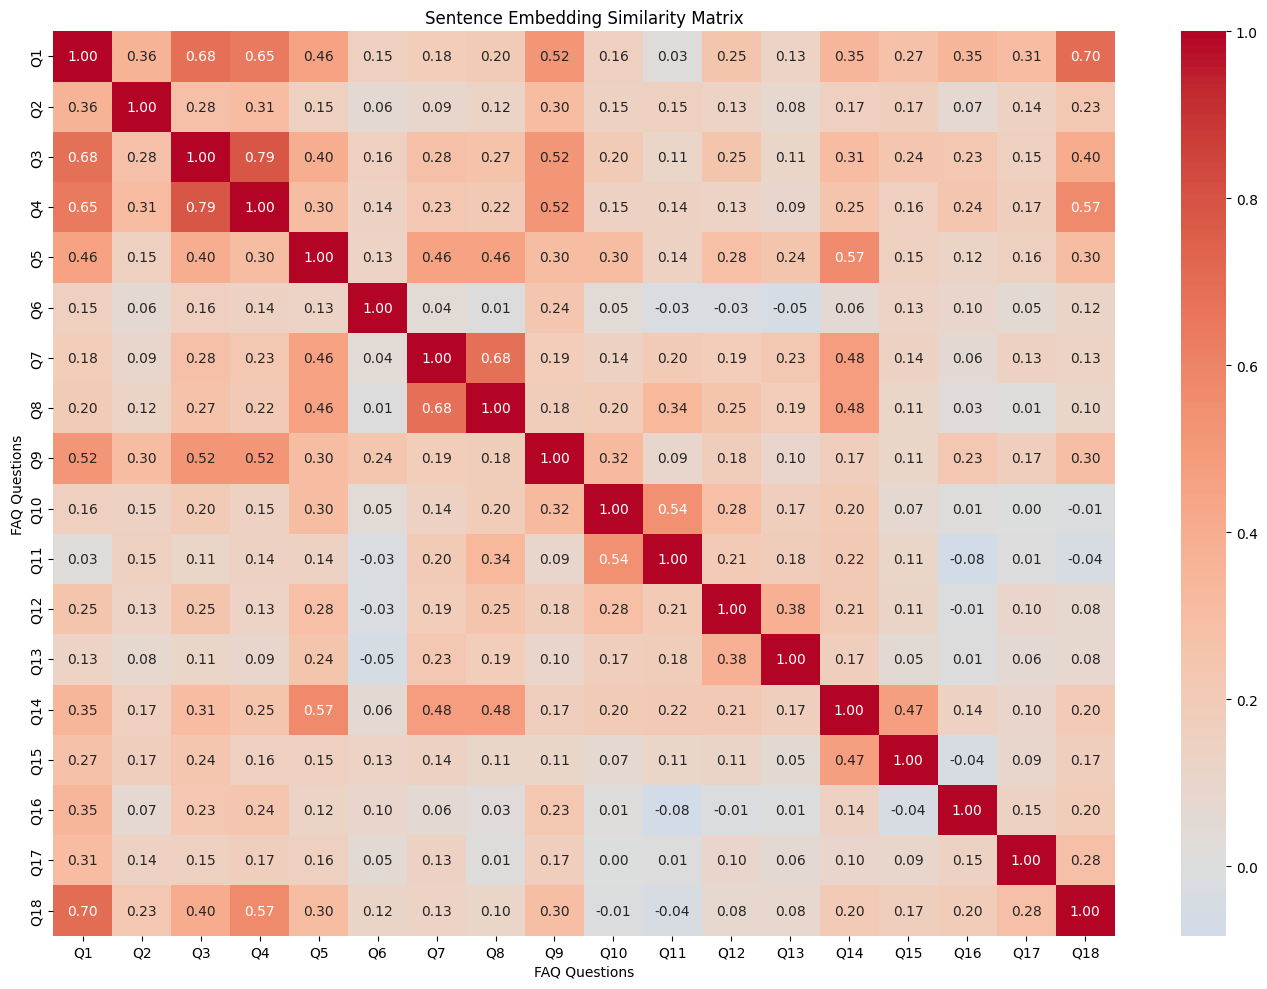

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

sns.heatmap(
    sentence_similarity_matrix,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    xticklabels=[f"Q{i+1}" for i in range(len(questions))],
    yticklabels=[f"Q{i+1}" for i in range(len(questions))],
    center=0
)

plt.title("Sentence Embedding Similarity Matrix")
plt.xlabel("FAQ Questions")
plt.ylabel("FAQ Questions")
plt.tight_layout()
plt.show()

### 4.5 Semantic Search using Sentence Embeddings

Semantic search retrieves relevant information based on the meaning of a query rather than relying only on exact keyword matches.

In this experiment:
1. Accept a new user query.
2. Convert the query into a sentence embedding.
3. Calculate cosine similarity against existing FAQ embeddings.
4. Retrieve the top 3 most relevant FAQ questions.

In [48]:
import numpy as np

# Define a new user query
user_query = "How do neural networks learn from data?"

# Generate embedding for the query
query_embedding = sentence_model.encode([user_query])

# Calculate similarity with existing FAQ questions
query_similarities = cosine_similarity(
    query_embedding,
    sentence_embeddings
)[0]

# Retrieve the top 3 matching questions
top_indices = np.argsort(query_similarities)[::-1][:3]

print("User Query:", user_query)
print("\nTop 3 Relevant FAQs:\n")

for rank, index in enumerate(top_indices, start=1):
    print(f"Rank {rank}")
    print("Question:", questions[index])
    print("Answer:", answers[index])
    print("Similarity:", round(query_similarities[index], 4))
    print("-" * 80)

User Query: How do neural networks learn from data?

Top 3 Relevant FAQs:

Rank 1
Question: How does a neural network learn?
Answer: A neural network learns by adjusting weights and biases through forward propagation and backpropagation.
Similarity: 0.8951
--------------------------------------------------------------------------------
Rank 2
Question: How is deep learning different from machine learning?
Answer: Deep learning uses multiple neural network layers, while traditional machine learning uses various algorithms.
Similarity: 0.5549
--------------------------------------------------------------------------------
Rank 3
Question: What is machine learning?
Answer: Machine learning enables computers to learn patterns from data and make predictions.
Similarity: 0.5508
--------------------------------------------------------------------------------


====================================================================================

# Contextual Embeddings using BERT

====================================================================================

## 5. Contextual Embeddings using BERT

Contextual embeddings represent words based on their surrounding context.

In this experiment, we will use the pretrained `bert-base-uncased` model to generate contextual representations.

Unlike Word2Vec, where a word generally has one learned vector regardless of its usage, BERT generates contextual representations that change depending on the surrounding words.

### Objectives
- Load a pretrained BERT model.
- Tokenize sentences using the BERT tokenizer.
- Extract contextual token embeddings.
- Compare the same word in different contexts.
- Calculate cosine similarity between contextual embeddings.

In [49]:
!pip install -q transformers

In [50]:
import torch
from transformers import AutoTokenizer, AutoModel

print("Transformers and PyTorch imported successfully!")

Transformers and PyTorch imported successfully!


### 5.1 Loading the Pretrained BERT Model

We will use `bert-base-uncased`, a pretrained BERT model.

BERT stands for Bidirectional Encoder Representations from Transformers.

It generates contextual representations by considering both left and right context around each token.

We will use:
- AutoTokenizer: Converts text into BERT-compatible tokens and token IDs.
- AutoModel: Generates contextual token embeddings.

In [51]:
# Load pretrained BERT tokenizer
bert_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

# Load pretrained BERT model
bert_model = AutoModel.from_pretrained("bert-base-uncased")

# Set model to evaluation mode
bert_model.eval()

print("BERT tokenizer and model loaded successfully!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT tokenizer and model loaded successfully!


### 5.2 Understanding Contextual Word Embeddings

The same word can have different meanings depending on its context.

We will examine the word "bank" in two sentences:

1. He deposited money at the bank.
2. He sat on the bank of the river.

In the first sentence, "bank" refers to a financial institution.

In the second sentence, "bank" refers to the land alongside a river.

Our objective is to observe how BERT generates different contextual embeddings for the same word.

In [52]:
# Define two sentences with different meanings of "bank"
sentence1 = "He deposited money at the bank."
sentence2 = "He sat on the bank of the river."

# Tokenize both sentences
tokens1 = bert_tokenizer.tokenize(sentence1)
tokens2 = bert_tokenizer.tokenize(sentence2)

print("Sentence 1:", sentence1)
print("Tokens 1:", tokens1)

print("\nSentence 2:", sentence2)
print("Tokens 2:", tokens2)

Sentence 1: He deposited money at the bank.
Tokens 1: ['he', 'deposited', 'money', 'at', 'the', 'bank', '.']

Sentence 2: He sat on the bank of the river.
Tokens 2: ['he', 'sat', 'on', 'the', 'bank', 'of', 'the', 'river', '.']


### 5.3 Converting Text into BERT Input

BERT requires token IDs rather than ordinary text.

The tokenizer performs the following operations:
- Adds special tokens `[CLS]` and `[SEP]`.
- Converts tokens into numerical token IDs.
- Creates attention masks to identify valid tokens.

These inputs are passed to BERT to generate contextual embeddings.

In [53]:
# Convert sentences into BERT-compatible inputs
inputs1 = bert_tokenizer(sentence1, return_tensors="pt")
inputs2 = bert_tokenizer(sentence2, return_tensors="pt")

# Display tokens and token IDs
print("Sentence 1:")
print("Tokens:", bert_tokenizer.convert_ids_to_tokens(inputs1["input_ids"][0]))
print("Token IDs:", inputs1["input_ids"][0].tolist())

print("\nSentence 2:")
print("Tokens:", bert_tokenizer.convert_ids_to_tokens(inputs2["input_ids"][0]))
print("Token IDs:", inputs2["input_ids"][0].tolist())

Sentence 1:
Tokens: ['[CLS]', 'he', 'deposited', 'money', 'at', 'the', 'bank', '.', '[SEP]']
Token IDs: [101, 2002, 14140, 2769, 2012, 1996, 2924, 1012, 102]

Sentence 2:
Tokens: ['[CLS]', 'he', 'sat', 'on', 'the', 'bank', 'of', 'the', 'river', '.', '[SEP]']
Token IDs: [101, 2002, 2938, 2006, 1996, 2924, 1997, 1996, 2314, 1012, 102]


### 5.4 Extracting Contextual Embeddings using BERT

We will pass both tokenized sentences through the pretrained BERT model.

BERT's final hidden layer produces a 768-dimensional contextual representation for every token.

We will extract the contextual embeddings corresponding to the word "bank" from both sentences.

These embeddings capture the meaning of "bank" based on its surrounding words.

In [54]:
# Generate contextual embeddings
with torch.no_grad():
    outputs1 = bert_model(**inputs1)
    outputs2 = bert_model(**inputs2)

# Extract final hidden-layer representations
embeddings1 = outputs1.last_hidden_state
embeddings2 = outputs2.last_hidden_state

# Locate the word "bank" in both sentences
bank_index1 = tokens1.index("bank")
bank_index2 = tokens2.index("bank")

# Extract contextual embeddings for "bank"
bank_embedding1 = embeddings1[0, bank_index1 + 1, :]
bank_embedding2 = embeddings2[0, bank_index2 + 1, :]

print("Sentence 1 - Bank embedding shape:", bank_embedding1.shape)
print("Sentence 2 - Bank embedding shape:", bank_embedding2.shape)

Sentence 1 - Bank embedding shape: torch.Size([768])
Sentence 2 - Bank embedding shape: torch.Size([768])


### 5.5 Comparing Contextual Embeddings using Cosine Similarity

We will calculate cosine similarity between the two contextual embeddings of the word "bank".

This helps us examine how BERT represents the same word in two different contexts.

In [55]:
from sklearn.metrics.pairwise import cosine_similarity

# Convert PyTorch tensors into NumPy arrays
bank_vector1 = bank_embedding1.numpy().reshape(1, -1)
bank_vector2 = bank_embedding2.numpy().reshape(1, -1)

# Calculate cosine similarity
contextual_similarity = cosine_similarity(
    bank_vector1,
    bank_vector2
)[0][0]

print("Context 1: Financial institution")
print("Context 2: River bank")
print("\nCosine Similarity:", round(contextual_similarity, 4))

Context 1: Financial institution
Context 2: River bank

Cosine Similarity: 0.5232


## 6. Comparison of Word, Sentence and Contextual Embeddings

| Feature | Word2Vec | Sentence Transformers | BERT |
|---|---|---|---|
| Representation | Individual words | Complete sentences | Individual tokens in context |
| Embedding dimensions | 100 | 384 | 768 |
| Model | Word2Vec Skip-Gram | all-MiniLM-L6-v2 | bert-base-uncased |
| Training | Trained on our FAQ dataset | Pretrained model | Pretrained model |
| Context awareness | Limited, static word vectors | Sentence-level semantic representation | Context-dependent token representations |
| Main use | Word similarity | Semantic search | Contextual language understanding |

### Experimental Observations

1. Word2Vec learned numerical representations for individual words.
2. Sentence Transformers successfully retrieved relevant FAQ questions using semantic similarity.
3. BERT generated different contextual representations for the same word in different sentences.
4. Cosine similarity helped us compare the generated embeddings.

--------------------------------------------------------


## Sinusoidal Positional Encoding

Sinusoidal positional encoding generates position-based vectors using sine and cosine functions.

It provides positional information to token embeddings, allowing the Transformer to understand the order of tokens in a sequence.

The positional encoding is added to the token embedding before it is passed into the Transformer layers.


In [56]:

# Purpose: Generate sinusoidal positional encodings.

import numpy as np
import matplotlib.pyplot as plt

# Define sequence length and embedding dimension
max_len = 50
d_model = 128

# Generate token positions
positions = np.arange(max_len)[:, np.newaxis]

# Calculate dimension indices
dimensions = np.arange(d_model)

# Calculate angle rates
angle_rates = 1 / np.power(
    10000,
    (2 * (dimensions // 2)) / d_model
)

# Calculate positional angles
angle_radians = positions * angle_rates

# Generate positional encoding matrix
positional_encoding = np.zeros((max_len, d_model))

# Apply sine to even dimensions
positional_encoding[:, 0::2] = np.sin(
    angle_radians[:, 0::2]
)

# Apply cosine to odd dimensions
positional_encoding[:, 1::2] = np.cos(
    angle_radians[:, 1::2]
)

print("Positional Encoding Shape:", positional_encoding.shape)

print("\nFirst 5 positional encoding vectors:")
print(positional_encoding[:5, :8])


Positional Encoding Shape: (50, 128)

First 5 positional encoding vectors:
[[ 0.          1.          0.          1.          0.          1.
   0.          1.        ]
 [ 0.84147098  0.54030231  0.76172041  0.64790587  0.68156135  0.73176098
   0.60469402  0.79645787]
 [ 0.90929743 -0.41614684  0.98704625 -0.16043596  0.99748     0.07094825
   0.96322662  0.26869029]
 [ 0.14112001 -0.9899925   0.51730572 -0.85580068  0.77827252 -0.62792665
   0.92964484 -0.36845688]
 [-0.7568025  -0.65364362 -0.31671543 -0.9485206   0.14153892 -0.98993269
   0.51761928 -0.85561105]]


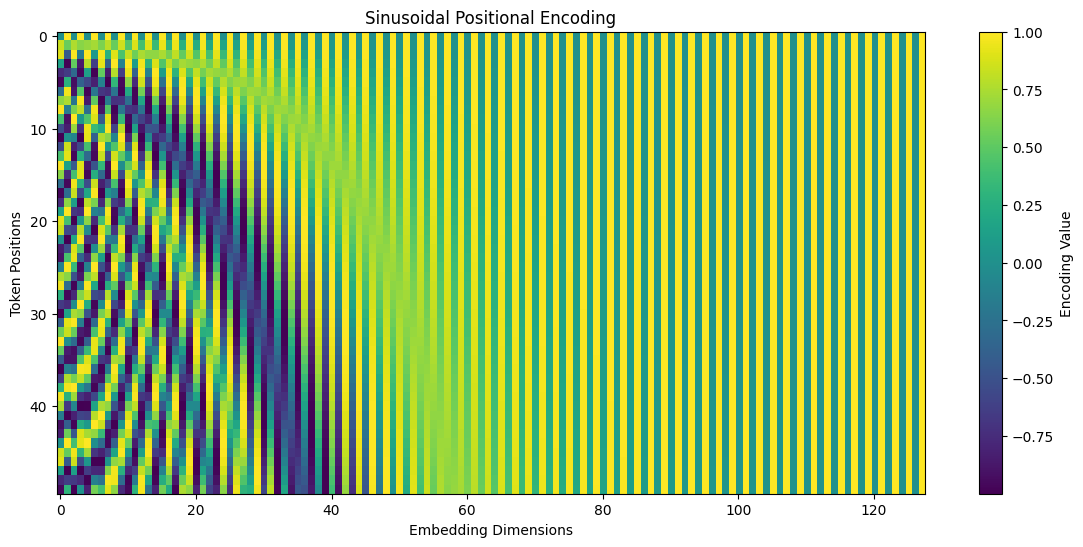

In [57]:
# Purpose: Visualize sinusoidal positional encoding.

plt.figure(figsize=(14, 6))

plt.imshow(
    positional_encoding,
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Encoding Value")
plt.xlabel("Embedding Dimensions")
plt.ylabel("Token Positions")
plt.title("Sinusoidal Positional Encoding")

plt.show()



## Combining Token Embeddings and Positional Encodings

A Transformer combines token embeddings with positional encodings to capture both the semantic meaning and positional information of each token.

The two matrices must have the same dimensions.

Final Input Representation = Token Embeddings + Positional Encodings


In [58]:

# Purpose: Create illustrative token embeddings.

tokens = ["The", "customer", "purchased", "a", "laptop"]

# Define embedding dimension
d_model = 128

# Generate illustrative token embeddings
rng = np.random.default_rng(seed=42)

token_embeddings = rng.normal(
    loc=0,
    scale=0.5,
    size=(len(tokens), d_model)
)

print("Tokens:", tokens)
print("Token Embeddings Shape:", token_embeddings.shape)

print("\nFirst 5 dimensions of each token embedding:")
print(token_embeddings[:, :5])


Tokens: ['The', 'customer', 'purchased', 'a', 'laptop']
Token Embeddings Shape: (5, 128)

First 5 dimensions of each token embedding:
[[ 0.15235854 -0.51999205  0.3752256   0.47028236 -0.97551759]
 [-0.31987577 -0.46328797 -0.1949049  -0.68834307  0.31757547]
 [ 0.21738304 -0.18807804 -0.06691148 -0.6874479  -0.11908687]
 [-0.80063897 -0.39706815  0.2198183   0.26209392  0.13813709]
 [ 0.04973874 -0.04305033  0.39540306  0.17232261  0.33416301]]


In [59]:

# Purpose: Select positional encodings for the five tokens.

sentence_positional_encoding = positional_encoding[:len(tokens), :]

print("Positional Encoding Shape:",
      sentence_positional_encoding.shape)

print("\nFirst 5 positional encoding values:")
print(sentence_positional_encoding[:, :5])


Positional Encoding Shape: (5, 128)

First 5 positional encoding values:
[[ 0.          1.          0.          1.          0.        ]
 [ 0.84147098  0.54030231  0.76172041  0.64790587  0.68156135]
 [ 0.90929743 -0.41614684  0.98704625 -0.16043596  0.99748   ]
 [ 0.14112001 -0.9899925   0.51730572 -0.85580068  0.77827252]
 [-0.7568025  -0.65364362 -0.31671543 -0.9485206   0.14153892]]


In [60]:

# Purpose: Combine token embeddings and positional encodings.

final_input_representation = (
    token_embeddings + sentence_positional_encoding
)

print("Final Input Representation Shape:",
      final_input_representation.shape)

print("\nFirst 5 dimensions of the combined representation:")
print(final_input_representation[:, :5])


Final Input Representation Shape: (5, 128)

First 5 dimensions of the combined representation:
[[ 0.15235854  0.48000795  0.3752256   1.47028236 -0.97551759]
 [ 0.52159522  0.07701434  0.56681551 -0.0404372   0.99913682]
 [ 1.12668046 -0.60422487  0.92013477 -0.84788387  0.87839313]
 [-0.65951896 -1.38706064  0.73712402 -0.59370675  0.91640961]
 [-0.70706376 -0.69669395  0.07868763 -0.77619799  0.47570193]]


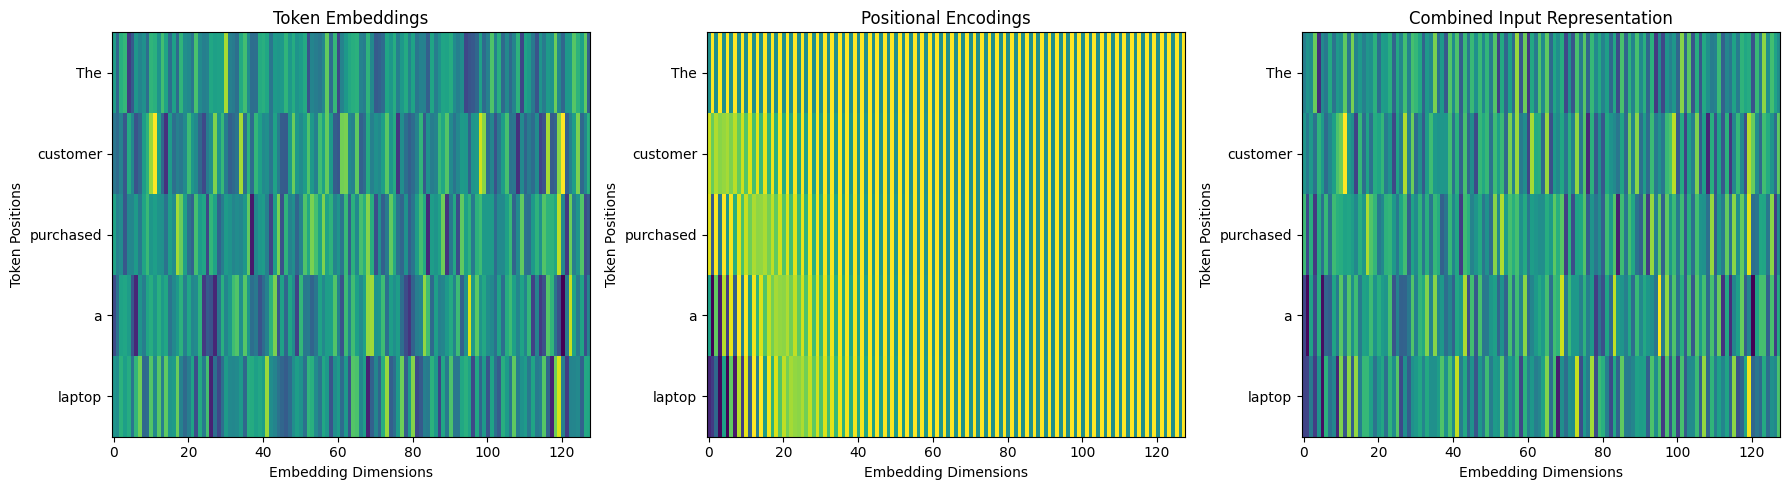

In [61]:

# Purpose: Compare token embeddings, positional encodings,
# and their combined representation.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

data = [
    token_embeddings,
    sentence_positional_encoding,
    final_input_representation
]

titles = [
    "Token Embeddings",
    "Positional Encodings",
    "Combined Input Representation"
]

for ax, matrix, title in zip(axes, data, titles):
    im = ax.imshow(matrix, aspect="auto", cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("Embedding Dimensions")
    ax.set_ylabel("Token Positions")
    ax.set_yticks(range(len(tokens)))
    ax.set_yticklabels(tokens)

plt.tight_layout()
plt.show()



### Experimental Observation

- Generated 128-dimensional token embeddings for five tokens.
- Generated sinusoidal positional encodings for the same five positions.
- Added both matrices element-wise.
- Obtained a final input representation with shape (5, 128).
- The combined representation contains both token-level information and positional information.

### Conclusion

Sinusoidal positional encoding helps Transformers incorporate sequence-order information without relying on recurrent processing. It uses sine and cosine functions at different frequencies to represent token positions.

---------------------------------------------------------------


# Final Conclusion

In this use case, we explored three major approaches to generating embeddings and studied how Transformers incorporate positional information through sinusoidal positional encoding.

### 1. Word Embeddings – Word2Vec

- Implemented the Word2Vec Skip-Gram model using Gensim.
- Trained the model on the FAQ questions and answers.
- Generated 100-dimensional word embeddings.
- Used cosine similarity to measure relationships between words.
- Retrieved similar words using the `most_similar()` method.

**Observation:** Word2Vec generates static word embeddings, meaning a word generally receives the same representation regardless of its context. Since our training dataset was relatively small, the similarity results are illustrative rather than representative of general language relationships.

### 2. Sentence Embeddings – Sentence Transformers

- Used the pretrained `all-MiniLM-L6-v2` model.
- Generated 384-dimensional sentence embeddings.
- Calculated pairwise cosine similarity between FAQ questions.
- Visualized sentence similarities using a heatmap.
- Implemented semantic search to retrieve the most relevant FAQ questions for a user query.

**Observation:** Sentence Transformers capture the semantic meaning of complete sentences rather than individual words. The semantic search experiment successfully retrieved relevant questions even when the query wording differed from the original FAQ.

### 3. Contextual Embeddings – BERT

- Loaded the pretrained `bert-base-uncased` model.
- Explored WordPiece tokenization and token IDs.
- Extracted contextual token representations from BERT's final hidden layer.
- Compared the word "bank" in two different contexts:
  - Financial context: "He deposited money at the bank."
  - Geographical context: "He sat on the bank of the river."
- Calculated cosine similarity between the two contextual representations.

**Observation:** BERT generates context-dependent token embeddings. The same word can have different representations depending on the surrounding words. This helps models understand different meanings of ambiguous words.

### 4. Sinusoidal Positional Encoding

- Implemented sinusoidal positional encoding using NumPy.
- Generated positional vectors using sine and cosine functions.
- Visualized positional patterns using a heatmap.
- Created illustrative token embeddings for a sample sentence.
- Combined token embeddings and positional encodings through element-wise addition.

**Observation:** Positional encoding provides information about token positions in a sequence. This is important because Transformers do not inherently process tokens sequentially like RNNs and LSTMs.

The final input representation combines semantic information from token embeddings with positional information from positional encodings.

### 5. Overall Learning Outcomes

Through this practical implementation, we understood the differences between word-level, sentence-level, and contextual embeddings.

| Approach | Representation | Main Application |
|---|---|---|
| Word2Vec | Static word embeddings | Word similarity |
| Sentence Transformers | Sentence embeddings | Semantic search |
| BERT | Contextual token embeddings | Context understanding |
| Sinusoidal Encoding | Positional vectors | Sequence-order information |

### Final Takeaway

This use case provided practical exposure to how text is converted into numerical representations and how different embedding techniques capture linguistic information at different levels.

We explored how Word2Vec represents individual words, how Sentence Transformers capture sentence-level meaning, how BERT generates context-aware token representations, and how sinusoidal positional encoding supplies sequence-order information to Transformers.

These concepts form an important foundation for modern Natural Language Processing (NLP) applications, including semantic search, information retrieval, question answering, and Retrieval-Augmented Generation (RAG).

**Overall, this experiment strengthened our understanding of embeddings, semantic similarity, contextual representations, and the fundamental input-processing mechanism of Transformer architectures.**

